# 19. Write a python program to implement edge detection using Sobel, Prewitt, and Canny operators.

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [7]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)
rows, cols = img.shape

In [8]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]])

In [9]:
sobel = np.zeros((rows, cols), dtype=np.uint8)
prewitt = np.zeros((rows, cols), dtype=np.uint8)

In [10]:
for i in range(1, rows - 1):
    for j in range(1, cols - 1):
        matrix = img[i-1:i+2, j-1:j+2]
        sx = np.sum(matrix * sobel_x)
        sy = np.sum(matrix * sobel_y)
        px = np.sum(matrix * prewitt_x)
        py = np.sum(matrix * prewitt_y)
        sobel[i][j] = min(255, (np.sqrt(sx**2 + sy**2)))
        prewitt[i][j] = min(255, (np.sqrt(px**2 + py**2)))

In [11]:
# Canny Edge Detection
canny = cv2.Canny(img, 100, 200)

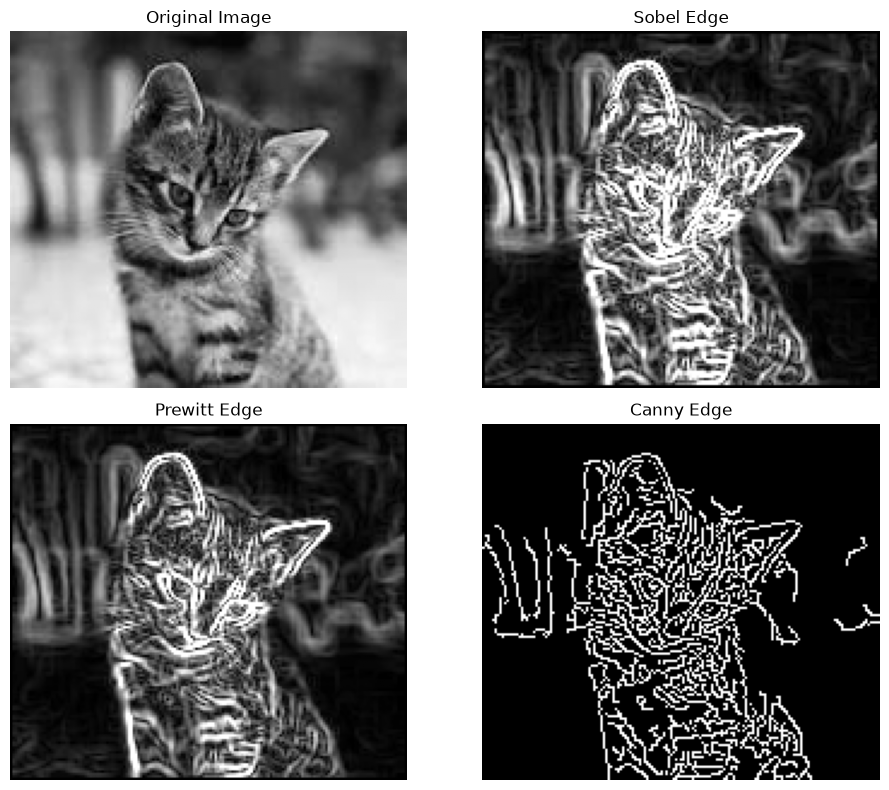

In [12]:
images = [img, sobel, prewitt, canny]

titles = ['Original Image', 'Sobel Edge',
          'Prewitt Edge', 'Canny Edge']

plt.figure(figsize=(10, 8))

for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()